In [1]:
import pandas as pd

df = pd.read_csv('../data/H2.csv')
print(df.shape)
print(df['IsCanceled'].value_counts())
df.head()

(79330, 31)
IsCanceled
0    46228
1    33102
Name: count, dtype: int64


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [5]:
drop_cols = ['ReservationStatus', 'ReservationStatusDate']
X = df.drop(columns=['IsCanceled'] + drop_cols)
y = df['IsCanceled']

X = pd.get_dummies(X)

print(X.shape)
X = X.fillna(X.median())
print("Missing values remaining:", X.isna().sum().sum())

(79330, 668)
Missing values remaining: 0


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(63464, 668) (15866, 668)


In [10]:

from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

clf = LogisticRegression(max_iter=2000, random_state=42)
clf.fit(X_train, y_train)
print("Training complete.")

Training complete.


In [15]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
print(f"CV Accuracy (5-fold): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Individual folds: {cv_scores.round(4)}")

CV Accuracy (5-fold): 0.8164 ± 0.0025
Individual folds: [0.8177 0.8157 0.8128 0.8202 0.8153]


In [11]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_pred = clf.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['Not Canceled', 'Canceled']))

Accuracy:  0.8139
Precision: 0.8241
Recall:    0.7020
F1-Score:  0.7582

              precision    recall  f1-score   support

Not Canceled       0.81      0.89      0.85      9271
    Canceled       0.82      0.70      0.76      6595

    accuracy                           0.81     15866
   macro avg       0.82      0.80      0.80     15866
weighted avg       0.81      0.81      0.81     15866



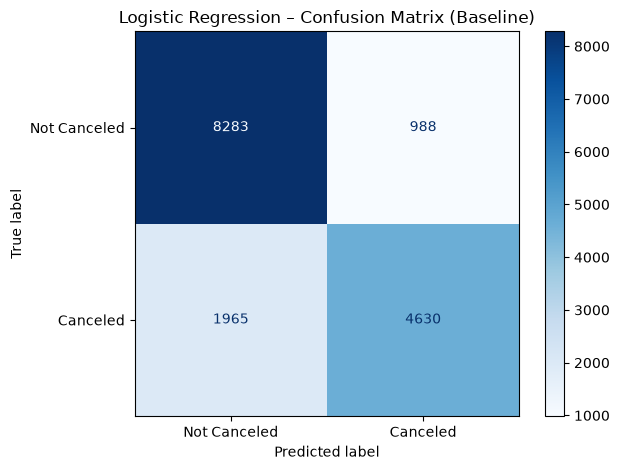

[[8283  988]
 [1965 4630]]


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Canceled', 'Canceled'])
disp.plot(cmap='Blues')
plt.title('Logistic Regression – Confusion Matrix (Baseline)')
plt.tight_layout()
plt.savefig('../outputs/phase1/confusion_matrix_baseline.png', dpi=150)
plt.show()
print(cm)

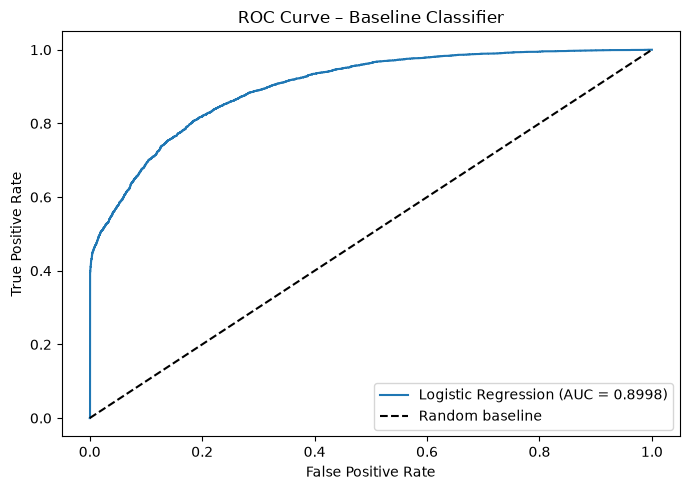

ROC-AUC: 0.8998


In [14]:
from sklearn.metrics import roc_auc_score, roc_curve

y_prob = clf.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_prob)

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Baseline Classifier')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/phase1/roc_curve_baseline.png', dpi=150)
plt.show()
print(f"ROC-AUC: {auc:.4f}")